# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [52]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.dates as mdates

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [53]:
mares_ano = pd.read_csv(DIR_RAW / "mares_2025.csv")
mares_prev = pd.read_csv(DIR_RAW / "mares_previsao.csv")
ondas = pd.read_csv(DIR_RAW / "ondas.csv")
vento = pd.read_csv(DIR_RAW / "vento.csv")

tabelas = {"mares_2025": mares_ano, "mares_previsao": mares_prev, "ondas": ondas, "vento": vento}
for nome, df in tabelas.items():
    print(f"{nome:15s} {len(df):5d} linhas | nulos: {df.isna().sum().sum()} | duplicadas: {df.duplicated().sum()}")

mares_2025       1410 linhas | nulos: 0 | duplicadas: 0
mares_previsao    236 linhas | nulos: 0 | duplicadas: 0
ondas             168 linhas | nulos: 0 | duplicadas: 0
vento             168 linhas | nulos: 0 | duplicadas: 0


In [54]:
for nome, df in tabelas.items():
    print(f"--- {nome}")
    print(df.dtypes.to_string(), "\n")

--- mares_2025
data                     str
hora                     str
tipo                     str
altura_m             float64
coeficiente            int64
coeficiente_nivel        str
idade_lua              int64 

--- mares_previsao
data                     str
hora                     str
tipo                     str
altura_m             float64
coeficiente            int64
coeficiente_nivel        str
idade_lua              int64 

--- ondas
data                 str
hora                 str
direcao              str
altura_onda_m    float64 

--- vento
data             str
hora             str
direcao          str
vento_kmh    float64 



In [55]:
mares_ano.head()

,data,hora,tipo,altura_m,coeficiente,coeficiente_nivel,idade_lua
0,2025-01-01,05:50,alta,2.4,81,alto,1
1,2025-01-01,12:00,baixa,0.4,81,alto,1
2,2025-01-01,18:07,alta,2.3,81,alto,1
3,2025-01-02,00:19,baixa,0.4,80,alto,2
4,2025-01-02,06:31,alta,2.4,80,alto,2


O arquivo mares_2025.csv tem 1410 linhas. Se todo dia tivesse 4 marés, seriam 365 x 4 = 1460, mas em 50 dias do ano só acontecem 3 marés (1460 - 50 = 1410), logo, o número bate com o período coletado.

O mares_previsao.csv tem 236 linhas, que são as marés de outubro (120) e de novembro (116) de 2026. Já ondas.csv e vento.csv têm 168 linhas cada, o que corresponde a 7 dias de previsão com uma leitura por hora (7 x 24 = 168).

Quanto aos tipos, as colunas numéricas (altura da maré, coeficiente, idade da lua, altura da onda e velocidade do vento) já vieram como número dos tipos inteiro e float, porque a troca da vírgula pelo ponto foi feita no scraping. As colunas de data e hora vieram como texto, já que o CSV não guarda o tipo de cada coluna. Isso é corrigido na etapa de limpeza.

Nenhuma das quatro tabelas tem colunas vazias, valores nulos ou linhas duplicadas.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [56]:
for df in (mares_ano, mares_prev, ondas, vento):
    df["datahora"] = pd.to_datetime(df["data"] + " " + df["hora"])

ondas = ondas.rename(columns={"direcao": "direcao_onda"})
vento = vento.rename(columns={"direcao": "direcao_vento"})

mares_ano.dtypes

data                            str
hora                            str
tipo                            str
altura_m                    float64
coeficiente                   int64
coeficiente_nivel               str
idade_lua                     int64
datahora             datetime64[us]
dtype: object

In [57]:
print("Altura da maré (m):  ", mares_ano["altura_m"].min(), "a", mares_ano["altura_m"].max())
print("Coeficiente:         ", mares_ano["coeficiente"].min(), "a", mares_ano["coeficiente"].max())
print("Idade da lua (dias): ", mares_ano["idade_lua"].min(), "a", mares_ano["idade_lua"].max())
print("Altura da onda (m):  ", ondas["altura_onda_m"].min(), "a", ondas["altura_onda_m"].max())
print("Vento (km/h):        ", vento["vento_kmh"].min(), "a", vento["vento_kmh"].max())

por_dia = mares_ano.groupby("data").size()
print("\nMarés por dia:", por_dia.value_counts().to_dict())

intervalo = mares_ano.sort_values("datahora")["datahora"].diff().dt.total_seconds() / 3600
print("Intervalo entre marés (h): média", round(intervalo.mean(), 2), "| mín", round(intervalo.min(), 2), "| máx", round(intervalo.max(), 2))

seq = mares_ano.sort_values("datahora")["tipo"]
print("Duas marés do mesmo tipo seguidas:", (seq == seq.shift()).sum())

Altura da maré (m):   0.0 a 2.8
Coeficiente:          27 a 114
Idade da lua (dias):  0 a 29
Altura da onda (m):   0.9 a 1.4
Vento (km/h):         16.0 a 28.0

Marés por dia: {4: 315, 3: 50}
Intervalo entre marés (h): média 6.21 | mín 5.15 | máx 7.28
Duas marés do mesmo tipo seguidas: 0


As colunas de data e hora foram agrupadas em uma, chamada datahora, e convertidas para o tipo datetime. Assim dá para ordenar os registros no tempo, calcular o intervalo entre eles e, mais adiante, juntar as tabelas usando a hora como referência.

O problema da vírgula decimal não apareceu aqui, porque já foi resolvido no scraping: a função numero_br, no scrape.py, troca a vírgula por ponto antes de salvar o CSV.

Também não foi preciso decidir o que fazer com nulos e com duplicatas, porque nenhuma tabela possuia valores ausentes ou duplicados. Elas poderiam ter aparecido por dois motivos: a página da tábua de marés repete a mesma tabela três vezes (as outras duas são versões para celular) e alguns dias têm uma célula vazia no lugar da quarta maré. O scraper já lia só a primeira tabela e pulava as células vazias, então nenhum desses casos chegou aos CSVs.

Aproveitei para renomear a coluna direcao nas tabelas de onda e de vento (para direcao_onda e direcao_vento), já que as duas tinham o mesmo nome e iam se misturar na junção.

Por fim, conferi se os valores fazem sentido. As faixas são plausíveis: a maré vai de 0 a 2,8 m, o coeficiente de 27 a 114, as ondas de 0,9 a 1,4 m e o vento de 16 a 28 km/h. Em 2025, foram 315 dias com 4 marés e 50 com 3, o que é normal, porque o ciclo de duas marés dura cerca de 24h50 e de vez em quando uma delas passa para o dia seguinte. O intervalo médio entre uma maré e a próxima foi de 6,21 horas (mais ou menos 6h13), que é o tempo esperado entre uma maré alta e uma baixa. E as marés altas e baixas sempre se alternam, sem nenhum caso de duas do mesmo tipo seguidas, o que indica que a classificação feita no scraping está correta.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

### Marés

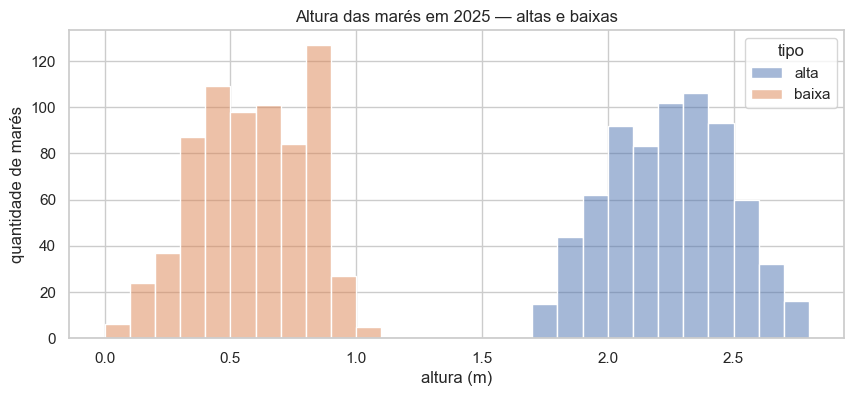

In [58]:
fig, ax = plt.subplots()
sns.histplot(data=mares_ano, x="altura_m", hue="tipo", bins=28, ax=ax)
ax.set(title="Altura das marés em 2025 — altas e baixas", xlabel="altura (m)", ylabel="quantidade de marés")
plt.show()

As marés formam dois grupos bem separados. As baixas ficam entre 0 e 1 m, a maioria perto de 0,5 m, e as altas entre 1,7 e 2,8 m, a maioria perto de 2,2 m. Nenhuma maré ficou entre 1 e 1,7 m. A diferença entre maré alta e baixa em João Pessoa é de quase 2 metros, o que é bastante.

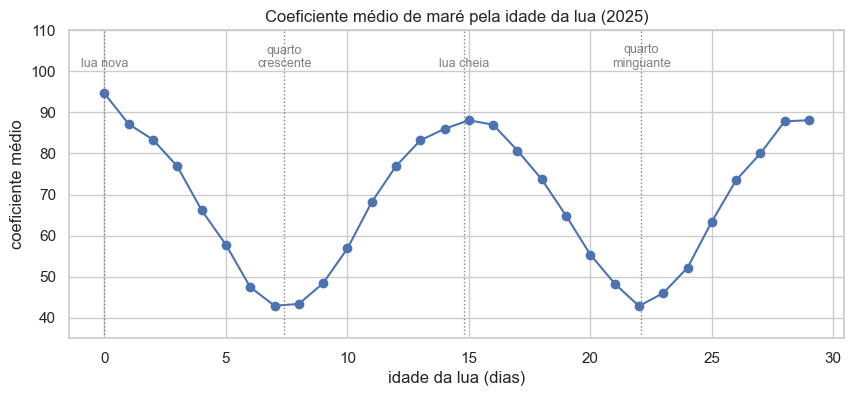

In [59]:
dias = mares_ano.drop_duplicates("data")
media_por_idade = dias.groupby("idade_lua")["coeficiente"].mean()

fig, ax = plt.subplots()
ax.plot(media_por_idade.index, media_por_idade.values, marker="o")
for x, rotulo in [(0, "lua nova"), (7.4, "quarto\ncrescente"), (14.8, "lua cheia"), (22.1, "quarto\nminguante")]:
    ax.axvline(x, color="gray", ls=":", lw=1)
    ax.text(x, 101, rotulo, ha="center", fontsize=9, color="gray")
ax.set(title="Coeficiente médio de maré pela idade da lua (2025)", xlabel="idade da lua (dias)", ylabel="coeficiente médio", ylim=(35, 110))
plt.show()

O coeficiente acompanha bem o ciclo da lua. Ele chega perto de 90 na lua nova (dia 0) e na lua cheia (por volta do dia 15) e cai para cerca de 43 nos quartos crescente e minguante (por volta dos dias 7 e 22). Na lua nova e na cheia, o Sol e a Lua estão alinhados e puxam a água na mesma direção (marés de sizígia). Nos quartos, eles ficam em ângulo reto e um efeito atrapalha o outro (marés de quadratura). Por isso o ciclo se repete duas vezes a cada mês lunar.

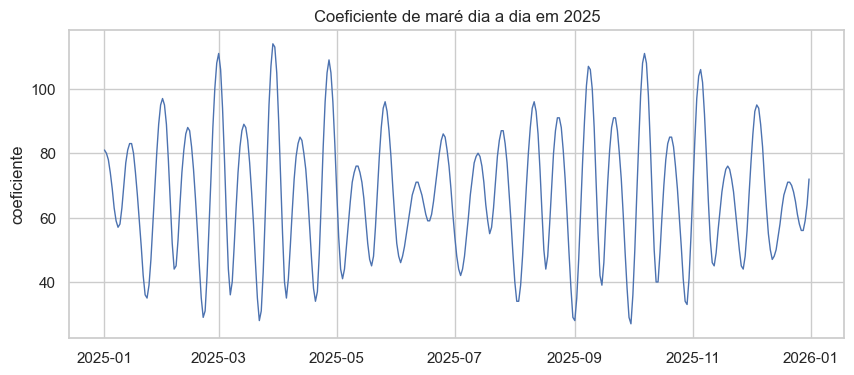

mes,1,2,3,4,5,6,7,8,9,10,11,12
mean,68.0,67.0,72.0,69.0,66.0,66.0,66.0,66.0,67.0,67.0,68.0,67.0
max,97.0,108.0,114.0,109.0,96.0,86.0,87.0,96.0,107.0,111.0,106.0,95.0


In [60]:
fig, ax = plt.subplots()
ax.plot(pd.to_datetime(dias["data"]), dias["coeficiente"], lw=1)
ax.set(title="Coeficiente de maré dia a dia em 2025", xlabel="", ylabel="coeficiente")
plt.show()

dias.assign(mes=pd.to_datetime(dias["data"]).dt.month).groupby("mes")["coeficiente"].agg(["mean", "max"]).round(0).T

Durante o ano todo o coeficiente sobe e desce duas vezes por mês, seguindo a lua, e a média de cada mês quase não muda (fica entre 66 e 72). O que muda é a altura dos picos. Os maiores coeficientes aparecem de fevereiro a abril e de setembro a novembro, chegando a 114 em março e 111 em outubro, enquanto em junho e julho o máximo não passa de 87. Esses períodos de picos maiores ficam em volta dos equinócios (março e setembro), quando o Sol está alinhado com o equador e reforça o efeito da Lua.

### Ondas

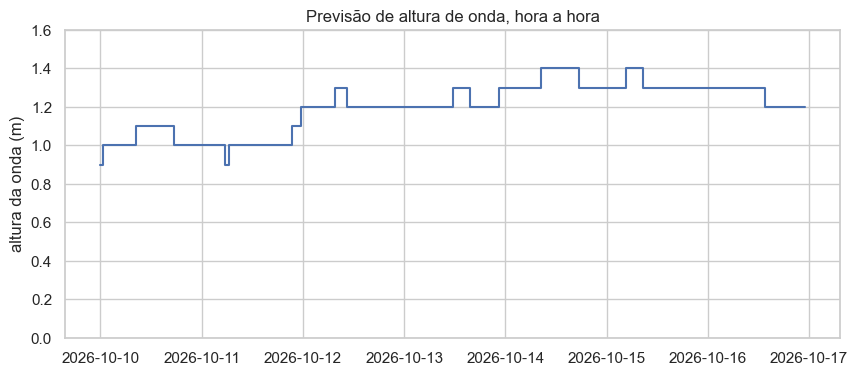

,min,max,mean
data,,,
2026-10-10,0.9,1.1,1.03
2026-10-11,0.9,1.1,1.00
2026-10-12,1.2,1.3,1.21
2026-10-13,1.2,1.3,1.22
2026-10-14,1.3,1.4,1.34
2026-10-15,1.3,1.4,1.32
2026-10-16,1.2,1.3,1.26


In [61]:
fig, ax = plt.subplots()
ax.plot(ondas["datahora"], ondas["altura_onda_m"], drawstyle="steps-mid")
ax.set(title="Previsão de altura de onda, hora a hora", ylabel="altura da onda (m)", ylim=(0, 1.6))
plt.show()

ondas.groupby("data")["altura_onda_m"].agg(["min", "max", "mean"]).round(2)

Na semana coletada as ondas ficaram entre 0,9 e 1,4 m, sempre vindas do leste (E ou ESE). A altura muda pouco ao longo de um mesmo dia, no máximo 0,2 m, e varia mais de um dia para o outro: o mar sai de cerca de 1 m nos dias 10 e 11 e chega a cerca de 1,3 m nos dias 14 e 15. Isso faz sentido, porque essas ondas são formadas longe da costa e não dependem do que acontece na praia em cada hora.

### Vento

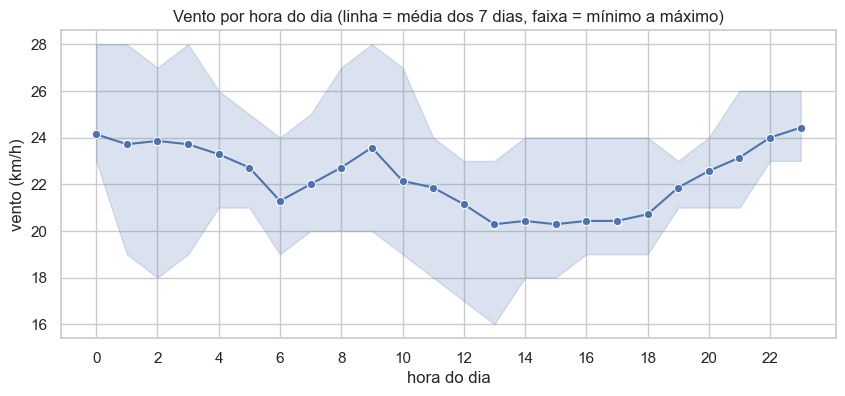

In [62]:
vento["hora_int"] = vento["datahora"].dt.hour
fig, ax = plt.subplots()
sns.lineplot(data=vento, x="hora_int", y="vento_kmh", errorbar=("pi", 100), marker="o", ax=ax)
ax.set(title="Vento por hora do dia (linha = média dos 7 dias, faixa = mínimo a máximo)",
       xlabel="hora do dia", ylabel="vento (km/h)", xticks=range(0, 24, 2))
plt.show()

O vento não chega a ficar fraco em nenhum horário, a média por hora fica entre 20 e 24 km/h. Mesmo assim dá para ver um padrão: as horas mais calmas são da 13h às 18h, com média perto de 20 km/h, e as mais fortes são no fim da noite e de madrugada, perto de 24 km/h. Também tem um pico isolado às 9h. A faixa sombreada mostra que a mesma hora pode mudar bastante de um dia para o outro. Às 13h, por exemplo, o vento variou de 16 a 23 km/h.

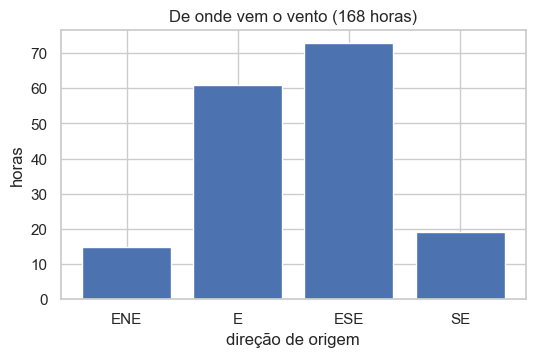

In [63]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ordem = ["ENE", "E", "ESE", "SE"]
contagem = vento["direcao_vento"].value_counts().reindex(ordem, fill_value=0)
ax.bar(contagem.index, contagem.values)
ax.set(title="De onde vem o vento (168 horas)", xlabel="direção de origem", ylabel="horas")
plt.show()

Em todas as 168 horas o vento veio do leste (ENE, E, ESE ou SE). Como a praia de João Pessoa fica de frente para o leste, o vento soprou do mar para a terra a semana inteira, o chamado vento maral. Para o surf esse é o vento ruim, porque ele empurra a onda por trás e deixa o mar mexido. O vento bom é o terral, que vem da terra (do oeste) e segura a onda, mas ele não apareceu nenhuma vez. Isso é o padrão dos ventos alísios, que sopram do leste no litoral do Nordeste.

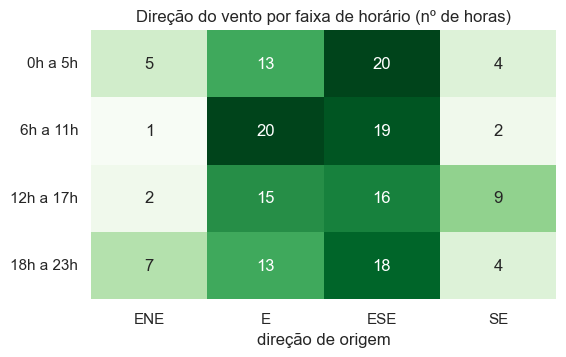

In [64]:
faixa = pd.cut(vento["hora_int"], bins=[-1, 5, 11, 17, 23], labels=["0h a 5h", "6h a 11h", "12h a 17h", "18h a 23h"])
tabela_dir = pd.crosstab(faixa, vento["direcao_vento"]).reindex(columns=["ENE", "E", "ESE", "SE"], fill_value=0)

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.heatmap(tabela_dir, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax)
ax.set(title="Direção do vento por faixa de horário (nº de horas)", xlabel="direção de origem", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.show()

A direção do vento praticamente não muda ao longo do dia. Em todas as faixas de horário ele vem quase sempre de E ou ESE. As diferenças são pequenas: à tarde (das 12h às 17h) aparece mais vento de SE, 9 das 42 horas, e à noite e de madrugada aparece um pouco de ENE. Em nenhum horário o vento virou para o oeste, então nesta semana não teve um momento do dia com vento terral. O que ajuda o surf é só o vento mais fraco da tarde.


## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

### Decisões da junção

O maior problema da junção é a maré. Onda e vento têm um valor por hora, mas o site só publica os picos da maré, isto é, os momentos de maré alta e de maré baixa, cerca de 4 por dia. Para ter a maré em todas as horas, foi preciso estimar os valores entre um pico e outro.

A opção mais simples seria repetir o último valor, mas isso supõe que a maré fica parada até o próximo pico, o que está bem longe da realidade, já que entre dois picos a água sobe ou desce quase 2 m. Interpolar em linha reta já é melhor, mas supõe que a maré sobe e desce sempre no mesmo ritmo, e por isso erra perto dos picos, onde a maré real desacelera. Guardar só se a maré está subindo ou descendo não faz nenhuma suposição sobre a altura, mas perde justamente essa informação.

Escolhi interpolar com uma curva de cosseno, que supõe que a maré muda devagar perto dos picos e mais rápido no meio do caminho, que é o formato da maré real. Ela ainda erra quando a subida e a descida não são simétricas, e não considera o efeito do vento e da pressão do ar no nível do mar. Mesmo assim, como o site informa a altura dos picos com só uma casa decimal, o erro deve ser de poucos centímetros, o que é pequeno perto da variação de quase 2 m entre maré alta e baixa. Além da altura estimada, guardei também se a maré está subindo ou descendo e quanto tempo falta para o próximo pico (horas_ate_pico).

Para juntar onda e vento, usei a coluna datahora e uma junção do tipo inner, que só mantém as horas presentes nas duas tabelas. Conferi antes (logo abaixo) e as duas previsões cobrem as mesmas 168 horas, então nenhuma hora foi perdida. Se elas não batessem, eu cortaria as horas incompletas em vez de mantê-las, porque uma hora sem onda ou sem vento não serve para avaliar se o mar está bom para surfar. O coeficiente e a idade da lua têm um valor por dia, por isso entram pela data.

Por fim, criei algumas colunas a partir da hora, pensando no que ajuda a responder quando os surfistas devem ir. A própria hora é importante porque a pergunta do projeto é sobre horários e o vento muda bastante ao longo do dia. O período (madrugada, manhã, tarde ou noite) resume isso em faixas, o que facilita uma recomendação do tipo "o melhor é ir à tarde". O dia da semana entra porque Felipe e Nicholas podem ter mais facilidade de vir no fim de semana. A coluna luz_do_dia marca as horas entre o nascer do sol, perto das 5h, e o pôr do sol, perto das 17h15, já que não dá para surfar no escuro. E vento_do_mar indica se o vento vem do mar ou da terra, que é o que mais muda a qualidade da onda para o surf.

In [65]:
eventos = mares_prev.sort_values("datahora").reset_index(drop=True)
t_ev = eventos["datahora"].to_numpy()
h_ev = eventos["altura_m"].to_numpy()

def mare_na_hora(t, metodo="cosseno"):
    """Altura da maré no instante t, a partir dos picos vizinhos."""
    i = np.searchsorted(t_ev, t) - 1          # último pico antes de t
    t0, t1, h0, h1 = t_ev[i], t_ev[i + 1], h_ev[i], h_ev[i + 1]
    f = (t - t0) / (t1 - t0)                  # fração do caminho entre os dois picos (0 a 1)
    if metodo == "linear":
        return h0 + (h1 - h0) * f
    return h0 + (h1 - h0) * (1 - np.cos(np.pi * f)) / 2

def proximo_pico(t):
    return eventos.iloc[np.searchsorted(t_ev, t)]

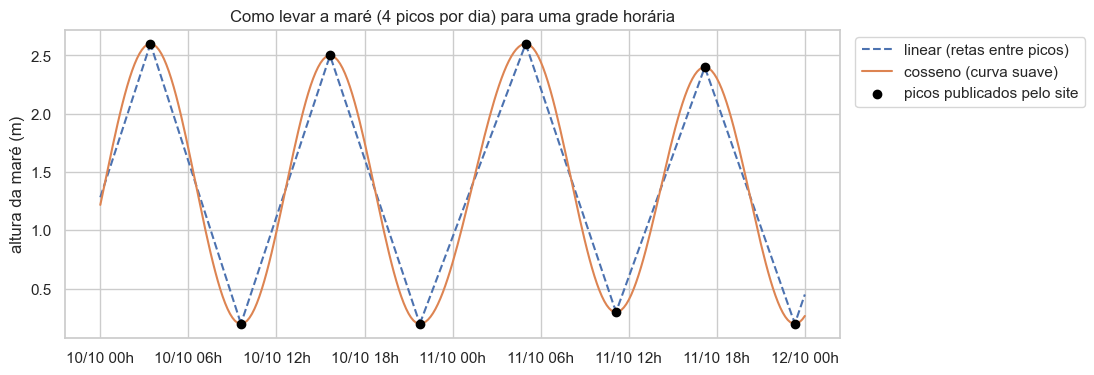

In [66]:
inicio = ondas["datahora"].min().normalize()     # primeiro dia da previsão
fim = inicio + pd.Timedelta(days=2)
t = pd.date_range(inicio, fim, freq="10min").to_numpy()
fig, ax = plt.subplots()
ax.plot(t, [mare_na_hora(x, "linear") for x in t], label="linear (retas entre picos)", ls="--")
ax.plot(t, [mare_na_hora(x) for x in t], label="cosseno (curva suave)")
picos = eventos[(eventos["datahora"] >= inicio) & (eventos["datahora"] <= fim)]
ax.scatter(picos["datahora"], picos["altura_m"], color="black", zorder=3, label="picos publicados pelo site")
ax.set(title="Como levar a maré (4 picos por dia) para uma grade horária", ylabel="altura da maré (m)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

As duas curvas passam pelos picos publicados pelo site (os pontos pretos), mas a linha reta forma bicos e passa rápido demais pelos extremos. A curva de cosseno fica mais tempo perto da maré cheia e da maré seca, que é o comportamento real da maré. Nas horas próximas dos picos, a diferença entre as duas chega a 25 cm.

In [67]:
conferencia = ondas.merge(vento, on="datahora", how="outer", indicator=True)
print(conferencia["_merge"].value_counts().to_dict())

df = ondas[["datahora", "altura_onda_m", "direcao_onda"]].merge(
    vento[["datahora", "vento_kmh", "direcao_vento"]], on="datahora", how="inner"
)

df["mare_altura_m"] = [mare_na_hora(t) for t in df["datahora"].to_numpy()]
prox = [proximo_pico(t) for t in df["datahora"].to_numpy()]
df["mare_estado"] = ["subindo" if p["tipo"] == "alta" else "descendo" for p in prox]
df["horas_ate_pico"] = [(p["datahora"] - t).total_seconds() / 3600 for p, t in zip(prox, df["datahora"])]


diario = mares_prev.drop_duplicates("data")[["data", "coeficiente", "idade_lua"]]
df["data"] = df["datahora"].dt.strftime("%Y-%m-%d")
df = df.merge(diario, on="data", how="left")


df["hora"] = df["datahora"].dt.hour
df["dia_semana"] = df["datahora"].dt.day_name(locale=None).map({
    "Monday": "seg", "Tuesday": "ter", "Wednesday": "qua", "Thursday": "qui",
    "Friday": "sex", "Saturday": "sáb", "Sunday": "dom"})
df["periodo"] = pd.cut(df["hora"], bins=[-1, 4, 11, 17, 23],
                       labels=["madrugada", "manhã", "tarde", "noite"]).astype(str)
df["luz_do_dia"] = df["hora"].between(5, 17)   # nascer ~5h, pôr do sol ~17h15 em out/2026

df["vento_do_mar"] = df["direcao_vento"].str.contains("E") & ~df["direcao_vento"].str.contains("W")

df = df.drop(columns="data")
print(df.shape, "| nulos:", df.isna().sum().sum())
df.head()

{'both': 168, 'left_only': 0, 'right_only': 0}
(168, 15) | nulos: 0


,datahora,altura_onda_m,direcao_onda,vento_kmh,direcao_vento,mare_altura_m,mare_estado,horas_ate_pico,coeficiente,idade_lua,hora,dia_semana,periodo,luz_do_dia,vento_do_mar
0,2026-10-10 00:00:00,0.9,ESE,24.0,SE,1.219251,subindo,3.416667,96,29,0,sáb,madrugada,False,True
1,2026-10-10 01:00:00,1.0,ESE,24.0,SE,1.814631,subindo,2.416667,96,29,1,sáb,madrugada,False,True
2,2026-10-10 02:00:00,1.0,ESE,24.0,ESE,2.306899,subindo,1.416667,96,29,2,sáb,madrugada,False,True
3,2026-10-10 03:00:00,1.0,ESE,23.0,ESE,2.573637,subindo,0.416667,96,29,3,sáb,madrugada,False,True
4,2026-10-10 04:00:00,1.0,ESE,22.0,ESE,2.547400,descendo,5.583333,96,29,4,sáb,madrugada,False,True


A tabela final ficou com 168 linhas, uma para cada hora, e 15 colunas, sem nenhum valor nulo. A conferência mostrou 168 horas em "both", então todas as horas de onda tinham vento correspondente e vice-versa.

A coluna vento_do_mar ficou verdadeira em todas as horas, porque o vento veio do leste a semana inteira. Mesmo sem variar nesta semana, mantive a coluna, porque em outros períodos pode aparecer vento terral e ela passa a fazer diferença.

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

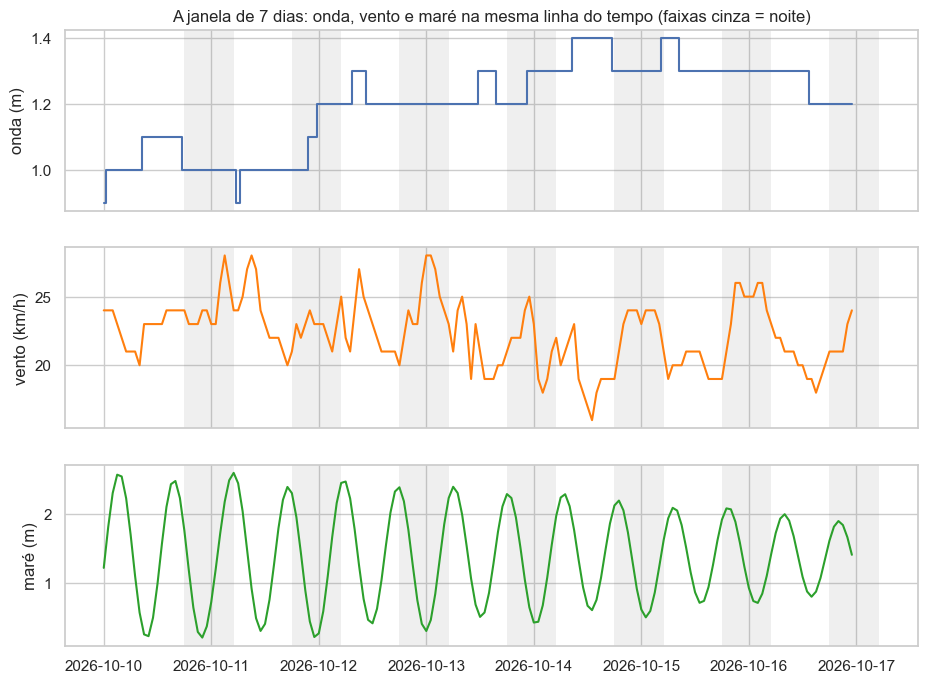

Correlação onda x vento: -0.39


In [68]:
fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axs[0].plot(df["datahora"], df["altura_onda_m"], drawstyle="steps-mid")
axs[0].set(ylabel="onda (m)", title="A janela de 7 dias: onda, vento e maré na mesma linha do tempo (faixas cinza = noite)")
axs[1].plot(df["datahora"], df["vento_kmh"], color="tab:orange")
axs[1].set(ylabel="vento (km/h)")
axs[2].plot(df["datahora"], df["mare_altura_m"], color="tab:green")
axs[2].set(ylabel="maré (m)")
for ax in axs:   # sombrear as noites
    for dia in pd.date_range(df["datahora"].min().normalize(), df["datahora"].max().normalize()):
        ax.axvspan(dia + pd.Timedelta(hours=18), dia + pd.Timedelta(hours=29), color="gray", alpha=0.12, lw=0)
plt.show()

print("Correlação onda x vento:", round(df["altura_onda_m"].corr(df["vento_kmh"]), 2))

Olhando as três variáveis juntas, dá para ver que cada uma tem um ritmo diferente. A maré sobe e desce duas vezes por dia, de forma bem regular. O vento muda de hora em hora e costuma cair no meio da tarde. Já a onda muda devagar, em degraus, de um dia para o outro.

Nesta semana, onda maior e vento mais fraco coincidiram, mas de um jeito específico. Entre os dias 14 e 16, o mar subiu para 1,3 a 1,4 m no mesmo período em que o vento ficou mais fraco, e a correlação entre as duas foi de -0,39. Só que a onda quase não muda dentro de um mesmo dia, então essa coincidência acontece entre os dias, e não entre as horas. Dentro de cada dia, a altura da onda é praticamente a mesma, e quem define o melhor horário é o vento, que é mais fraco à tarde.

Essa coincidência entre os dias também parece ser por acaso. Se o vento influenciasse a onda aqui, o esperado seria mais vento gerar onda maior, e não menor. As ondas que chegam em João Pessoa são formadas longe da costa, enquanto o vento medido é o local, então com só 7 dias não dá para dizer que uma coisa depende da outra.

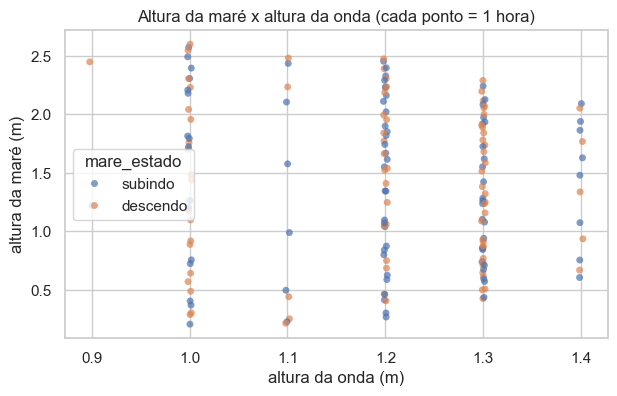

Correlação maré x onda: -0.07


In [69]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=df, x="altura_onda_m", y="mare_altura_m", hue="mare_estado", alpha=0.7, ax=ax, native_scale=True, jitter=0.02)
ax.set(title="Altura da maré x altura da onda (cada ponto = 1 hora)", xlabel="altura da onda (m)", ylabel="altura da maré (m)")
plt.show()

print("Correlação maré x onda:", round(df["mare_altura_m"].corr(df["altura_onda_m"]), 2))

Não aparece relação entre a altura da maré e a altura da onda. Para cada altura de onda existem horas com maré alta e com maré baixa, subindo e descendo, e a correlação ficou praticamente zero (-0,07). Isso era esperado, porque a maré é causada pela Lua e pelo Sol, enquanto a onda é formada pelo vento em alto-mar. Para o surf, a maré tem mais influência em onde e como a onda quebra, principalmente em praias com recifes como as de João Pessoa, do que no tamanho da onda que chega.

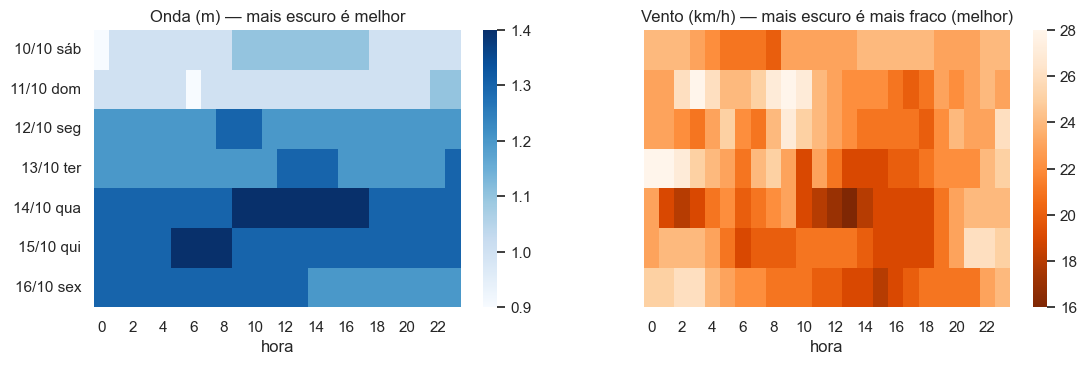

In [70]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, col, cmap, titulo in [
    (axs[0], "altura_onda_m", "Blues", "Onda (m) — mais escuro é melhor"),
    (axs[1], "vento_kmh", "Oranges_r", "Vento (km/h) — mais escuro é mais fraco (melhor)"),
]:
    tabela = df.pivot_table(index=df["datahora"].dt.strftime("%d/%m ") + df["dia_semana"], columns="hora", values=col)
    sns.heatmap(tabela, cmap=cmap, ax=ax, cbar=True)
    ax.set(title=titulo, xlabel="hora", ylabel="")
plt.show()

Comparando os dois mapas, o período que mais se destaca é a quarta-feira, dia 14, entre 10h e 17h. Foi quando a semana teve as maiores ondas (1,4 m) e o vento mais fraco, entre 16 e 19 km/h, chegando a 16 km/h às 13h. Depois vem a manhã de quinta, dia 15, das 5h às 8h, também com onda de 1,4 m e vento entre 19 e 21 km/h. Os piores dias foram o sábado e o domingo, 10 e 11, com as menores ondas da semana (de 0,9 a 1,1 m) e vento chegando a 28 km/h.

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [71]:
df.to_csv(DIR_PROC / "dataset.csv", index=False)
print(f"{len(df)} linhas x {df.shape[1]} colunas salvas em {DIR_PROC / 'dataset.csv'}")
print(list(df.columns))

168 linhas x 15 colunas salvas em ../data/processed/dataset.csv
['datahora', 'altura_onda_m', 'direcao_onda', 'vento_kmh', 'direcao_vento', 'mare_altura_m', 'mare_estado', 'horas_ate_pico', 'coeficiente', 'idade_lua', 'hora', 'dia_semana', 'periodo', 'luz_do_dia', 'vento_do_mar']


## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?

Na semana coletada, de 10 a 16 de outubro de 2026, o mar ficou entre pequeno e médio, com ondas de 0,9 a 1,4 m vindas do leste. O vento foi moderado, entre 16 e 28 km/h, e soprou do mar para a terra o tempo todo, que é o padrão dos ventos alísios no litoral do Nordeste. As ondas cresceram ao longo da semana e o vento costuma ficar mais fraco à tarde, entre 13h e 18h, então o melhor momento foi a tarde de quarta, dia 14. Como não teve nenhuma hora de vento terral, que é o que deixa a onda realmente boa, nenhum momento da semana chegou a ser excelente para surfar. Sobre a maré, os dados de 2025 mostram que ela é bem regular, com quase 2 m de diferença entre a alta e a baixa, e fica mais forte na lua nova e na lua cheia, principalmente perto dos equinócios.

A decisão que mais influencia o resultado é a forma como a maré foi levada para a grade horária. Ela é a única variável que o site não fornece hora a hora, então os valores de maré da tabela final são estimativas feitas por mim, e não dados reais. Se eu tivesse repetido o último valor, a maré ficaria parada por cerca de 6 horas, e qualquer critério baseado na altura da maré, como preferir a meia-maré, daria resultados errados. Com a curva de cosseno, o erro fica em poucos centímetros.

Esses dados não permitem dizer qual é a melhor época do ano para voltar, porque temos só 7 dias de onda e vento. O site não guarda histórico da previsão, então não sabemos como o mar e o vento se comportam em outros meses, e o ano de 2025 só traz informação sobre a maré. Também não dá para afirmar que a relação entre onda e vento encontrada é real, já que ela vem de uma única semana e não tem explicação física. Além disso, os dados são uma previsão, e não uma medição, e a previsão dos últimos dias da janela tende a ser menos confiável que a dos primeiros. Por último, os valores valem para João Pessoa como um todo, e cada praia reage de um jeito diferente à maré e à direção da onda.